# 🫀 Exploratory Data Analysis of Stroke Dataset

## Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on a real-world stroke dataset using Python, Pandas, and Matplotlib.

The analysis focuses on understanding dataset structure, identifying missing values, examining numerical and categorical variables, and discovering patterns and relationships associated with stroke.



In [28]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:


sns.set_style("whitegrid")
sns.set_context("talk")   # makes text bigger & clean

plt.rcParams["figure.figsize"] = (8,5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

## Load Dataset

In [30]:
df=pd.read_csv("stroke_dataset.csv")

## 🔍 Data Understanding

In [31]:
df.shape

(5110, 12)

In [32]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


In [33]:
df.head(3)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1


In [34]:
df.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [36]:
# Memory Usage Analysis

print("Memory Usage of Each Column:")

print(df.memory_usage(deep=True))

print("\nTotal Memory Usage:",
      df.memory_usage(deep=True).sum(), "bytes")

Memory Usage of Each Column:
Index                   132
id                    40880
gender               276819
age                   40880
hypertension          40880
heart_disease         40880
ever_married         263963
work_type            292528
Residence_type       275940
avg_glucose_level     40880
bmi                   40880
smoking_status       301911
stroke                40880
dtype: int64

Total Memory Usage: 1697453 bytes


In [37]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [38]:
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [39]:
# Missing Values Percentage Analysis

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Values Percentage:")
print(missing_percentage)

Missing Values Percentage:
id                   0.000000
gender               0.000000
age                  0.000000
hypertension         0.000000
heart_disease        0.000000
ever_married         0.000000
work_type            0.000000
Residence_type       0.000000
avg_glucose_level    0.000000
bmi                  3.933464
smoking_status       0.000000
stroke               0.000000
dtype: float64


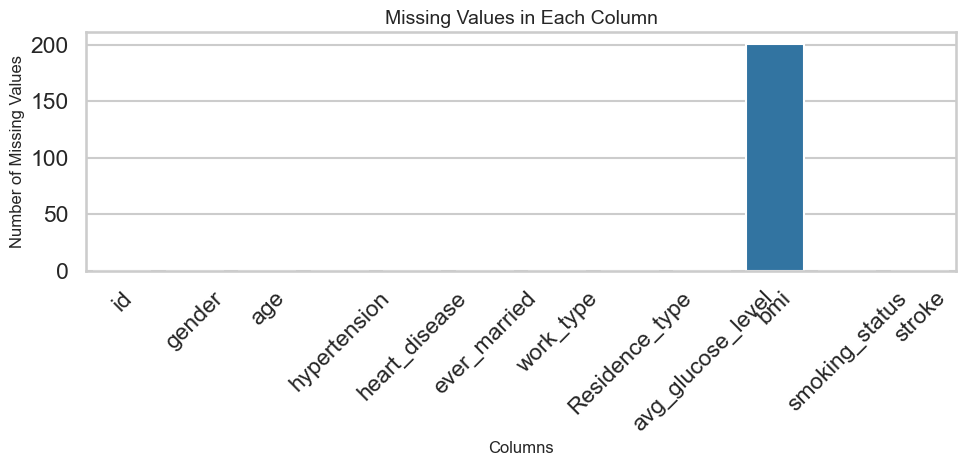

In [40]:
# Missing Values Analysis Visualization

missing_values = df.isnull().sum()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_values.index,
    y=missing_values.values
)

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [41]:
# Categorical Columns Value Counts

categorical_columns = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status',
    'stroke'
]

for column in categorical_columns:

    print("\nValue Counts for", column)

    print(df[column].value_counts())


Value Counts for gender
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Value Counts for ever_married
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

Value Counts for work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Value Counts for Residence_type
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

Value Counts for smoking_status
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64

Value Counts for stroke
stroke
0    4861
1     249
Name: count, dtype: int64


## 🧹 Data Cleaning

In [42]:
df.drop("id",axis=1,inplace=True)

In [43]:
df["bmi"]=df.groupby("gender")["bmi"].transform(lambda x: x.fillna(x.median()))

In [44]:
df.isnull().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

## 📊 Exploratory Data Analysis

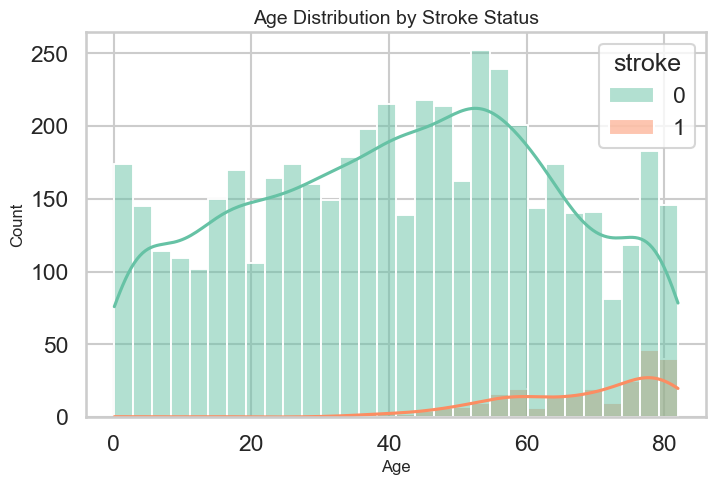

In [45]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="age", hue="stroke", bins=30, kde=True, palette="Set2")

plt.title("Age Distribution by Stroke Status")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

### Interpretation

The age distribution shows that the dataset contains people from different age groups. Stroke cases are more noticeable among older individuals compared to younger individuals. This suggests that age may be an important factor associated with stroke in this dataset.

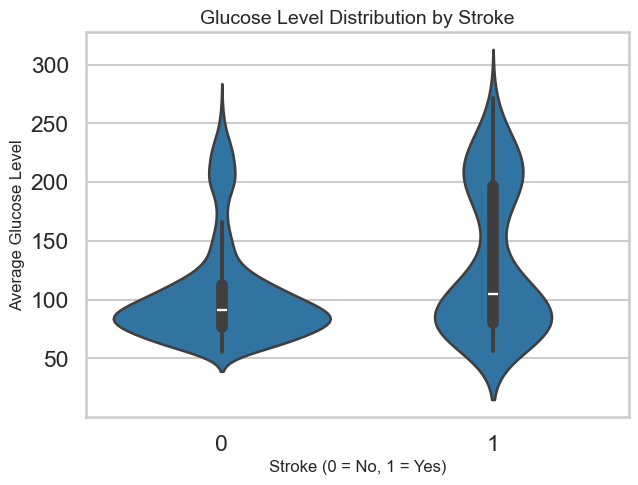

In [46]:
# Glucose Level Distribution by Stroke

plt.figure(figsize=(7, 5))

sns.violinplot(
    x="stroke",
    y="avg_glucose_level",
    data=df
)

plt.title("Glucose Level Distribution by Stroke")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Average Glucose Level")

plt.show()

### Interpretation

The violin plot compares glucose level distributions between people with and without stroke. It helps identify differences in glucose levels and their spread across the two groups. However, this visualization alone cannot establish that glucose levels cause stroke.

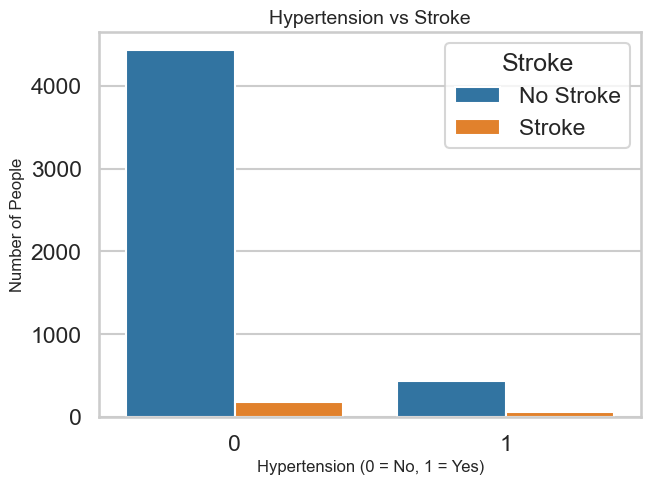

In [47]:
# Hypertension vs Stroke

plt.figure(figsize=(7, 5))

sns.countplot(
    x="hypertension",
    hue="stroke",
    data=df
)

plt.title("Hypertension vs Stroke")
plt.xlabel("Hypertension (0 = No, 1 = Yes)")
plt.ylabel("Number of People")

plt.legend(
    title="Stroke",
    labels=["No Stroke", "Stroke"]
)

plt.show()

### Interpretation

The count plot compares stroke cases among people with and without hypertension. It helps us understand how stroke records are distributed across hypertension categories. The number of people in each category should also be considered when interpreting the results.

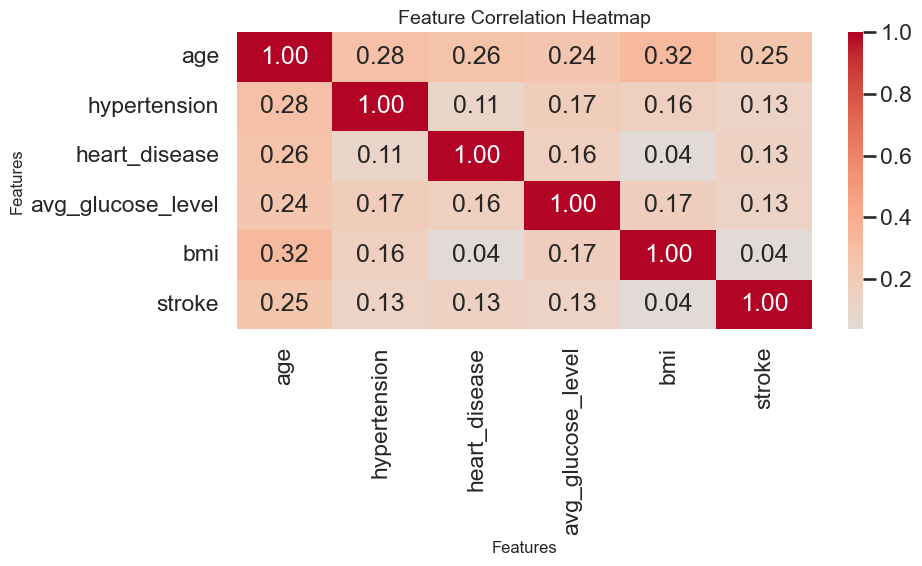

In [48]:
# Feature Correlation Heatmap

plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=[np.number])

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### Interpretation

The correlation heatmap shows the relationships between numerical features. It helps identify positive and negative correlations between variables. Correlation values indicate statistical relationships but do not prove causation.

In [49]:
pd.crosstab(df["heart_disease"], df["stroke"], normalize='index') * 100

stroke,0,1
heart_disease,,
0,95.821266,4.178734
1,82.971014,17.028986


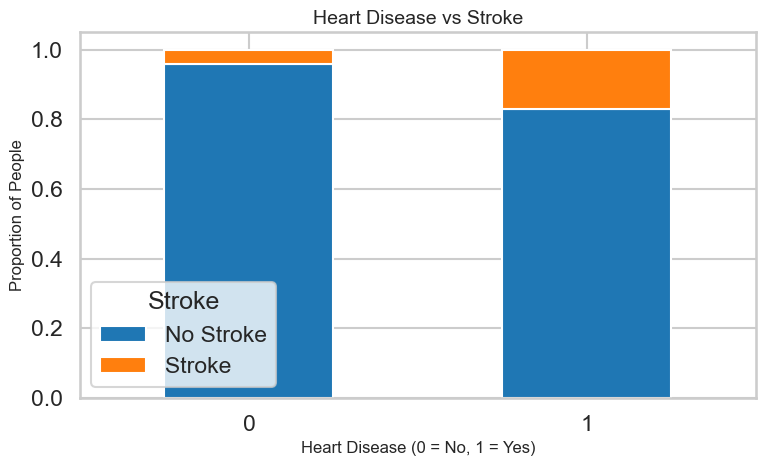

In [50]:
# Heart Disease vs Stroke

pd.crosstab(
    df["heart_disease"],
    df["stroke"],
    normalize='index'
).plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Heart Disease vs Stroke")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Proportion of People")

plt.legend(
    title="Stroke",
    labels=["No Stroke", "Stroke"]
)

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Interpretation

The stacked bar chart shows that 17.03% of individuals with heart disease had a stroke, compared to 4.18% of individuals without heart disease. This indicates a higher proportion of stroke cases among individuals with heart disease in this dataset.

## Final Findings

1. The dataset contains 5,110 records and 12 columns, providing information about demographic and health-related factors.

2. The BMI column contains 201 missing values, representing approximately 3.93% of the dataset. These missing values were handled using gender-wise median imputation.

3. The dataset contains 249 stroke cases and 4,861 non-stroke cases, indicating a significant class imbalance.

4. The age distribution visualization suggests that stroke cases are more noticeable among older individuals.

5. The heart disease comparison shows that the proportion of stroke cases is higher among individuals with heart disease (17.03%) than those without heart disease (4.18%).

# Conclusion

Exploratory Data Analysis helped us understand the structure, quality, distributions and relationships within the Stroke Risk Prediction dataset.

The visualizations provided useful insights into age, glucose levels, hypertension, heart disease and stroke patterns.

This analysis provides a foundation for further data preprocessing and machine learning.